# Practical 1 - Image Basics

Aim: Read, display and write an image, inspect its properties, convert it to grayscale and read a video.

Name: Navjot Singh
Roll No: 2025010071
Image shape: (600, 900, 3)
Image size: 1620000
Image type: uint8


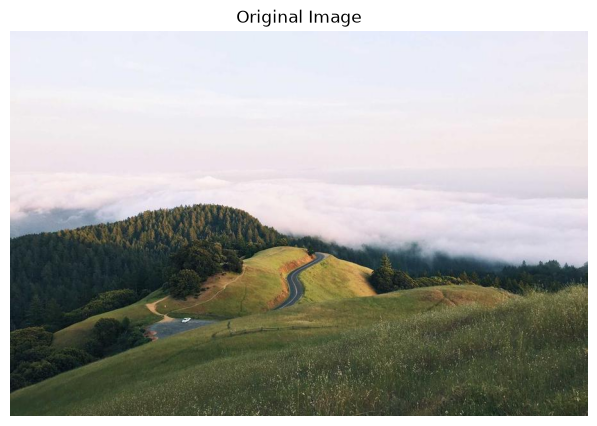

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Name: Navjot Singh")
print("Roll No: 2025010071")

# read the image
img = cv2.imread("images/navjot_a.jpg")
print("Image shape:", img.shape)
print("Image size:", img.size)
print("Image type:", img.dtype)

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

In [2]:
import os
os.makedirs("output", exist_ok=True)

cv2.imwrite("output/lab1_saved.jpg", img)
saved = cv2.imread("output/lab1_saved.jpg")

print("Saved image shape:", saved.shape)
print("Pixel at (0, 0) BGR:", img[0, 0])
print("Pixel at (100, 200) BGR:", img[100, 200])

Saved image shape: (600, 900, 3)
Pixel at (0, 0) BGR: [248 236 234]
Pixel at (100, 200) BGR: [248 243 244]


In [3]:
# save in other formats
cv2.imwrite("output/lab1_image.png", img)
cv2.imwrite("output/lab1_image.bmp", img)
cv2.imwrite("output/lab1_image.tiff", img)

for ext in ["png", "bmp", "tiff"]:
    path = "output/lab1_image." + ext
    converted = cv2.imread(path)
    print(ext, "shape:", converted.shape, "size:", os.path.getsize(path), "bytes")

png shape: (600, 900, 3) size: 627326 bytes
bmp shape: (600, 900, 3) size: 1620054 bytes
tiff shape: (600, 900, 3) size: 580000 bytes


Original shape: (600, 900, 3)
Resized shape: (300, 400, 3)
Half shape: (300, 450, 3)


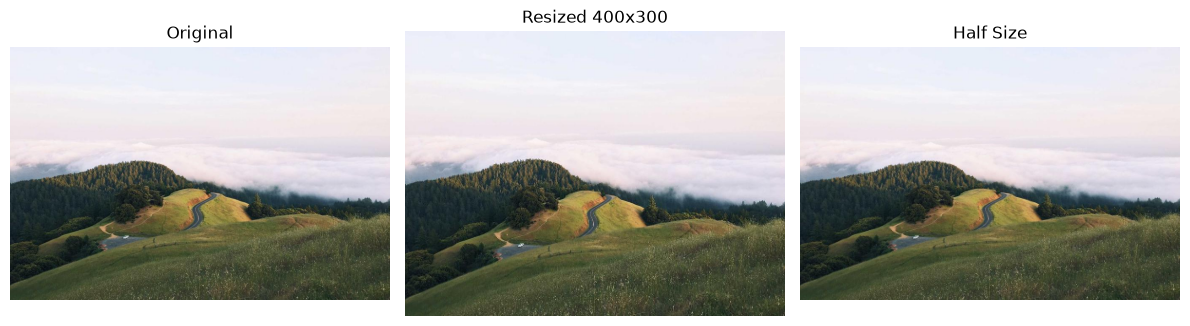

In [4]:
# resize to a fixed size and by half
resized = cv2.resize(img, (400, 300))
half = cv2.resize(img, None, fx=0.5, fy=0.5)

print("Original shape:", img.shape)
print("Resized shape:", resized.shape)
print("Half shape:", half.shape)

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title("Resized 400x300")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(half, cv2.COLOR_BGR2RGB))
plt.title("Half Size")
plt.axis("off")

plt.tight_layout()
plt.show()

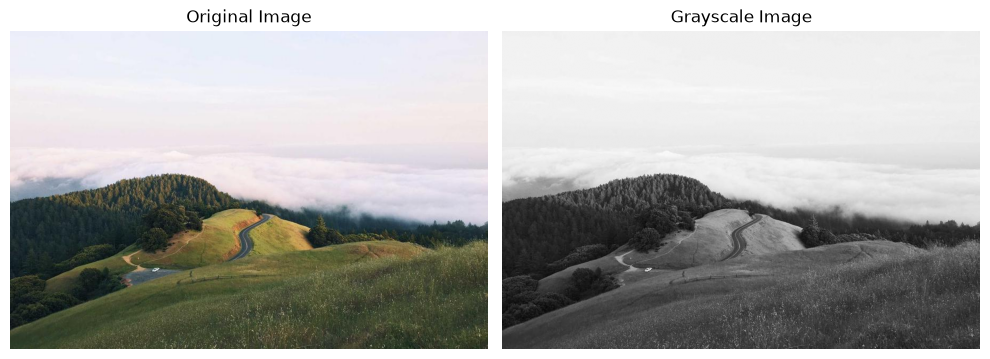

In [5]:
# convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
cv2.imwrite("output/lab1_gray.jpg", gray)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

Video opened: True
FPS: 10.0
Total frames read: 30


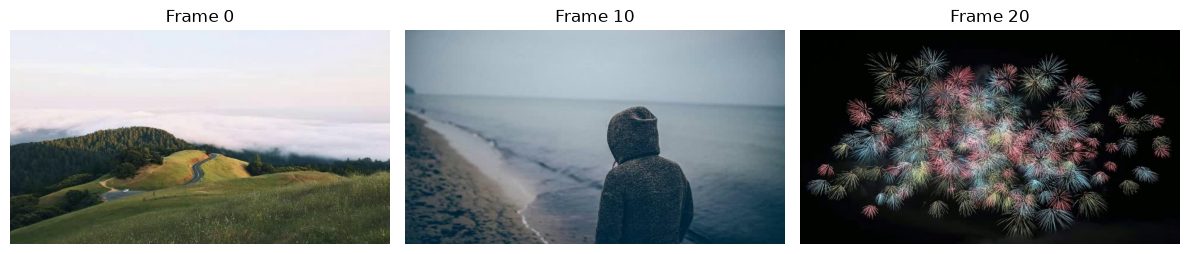

In [6]:
cap = cv2.VideoCapture("videos/sample_video.mp4")
print("Video opened:", cap.isOpened())
print("FPS:", cap.get(cv2.CAP_PROP_FPS))

frames = []
count = 0
while True:
    ret, frame = cap.read()
    if not ret:
        break
    if count in [0, 10, 20]:
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    count = count + 1
cap.release()

print("Total frames read:", count)

plt.figure(figsize=(12, 4))
for i in range(len(frames)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(frames[i])
    plt.title("Frame " + str(i * 10))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# extract every 10th frame
cap = cv2.VideoCapture("videos/sample_video.mp4")
count = 0
saved_count = 0

while True:
    ret, frame = cap.read()
    if not ret:
        break
    if count % 10 == 0:
        cv2.imwrite("output/lab1_frame_" + str(saved_count) + ".jpg", frame)
        saved_count = saved_count + 1
    count = count + 1
cap.release()

print("Frames saved:", saved_count)

Frames saved: 3
